# 02 · Generators, Retrieval-demo and Adapter grids
Main family comparisons use **Uniform aggregation** and include the frozen identity once.
Main scope: six checkpoints, six datasets, four horizons, three seeds (432 cells).
The Adapter grid sweep below is a distinct 72-cell experiment with a **Risk regressor**.


In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'artifacts/manifest.json').exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ttc4ts.results import (checked_path, load_snapshot, geometric, summarize,
    main_summary, lw_budget_summary, uncertainty_summary, MODELS, MODEL_LABELS, METHODS, METHOD_LABELS)
%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
print('Offline mode: numerical snapshots are verified against the released SHA-256 manifest.')


Offline mode: numerical snapshots are verified against the released SHA-256 manifest.


,method,relative_mse,relative_mae,wins,cells
0,backbone,1.00000,1.00000,0,432
1,families/adapter,0.98812,1.00906,270,432
2,families/augmentation,0.96211,1.00959,325,432
3,families/retrieval,0.95304,0.98912,339,432
4,families/adapter+augmentation,0.97490,1.00323,380,432
5,families/adapter+retrieval,0.97355,1.00063,390,432
6,families/augmentation+retrieval,0.94235,0.99151,396,432
7,families/adapter+augmentation+retrieval,0.96505,0.99739,406,432


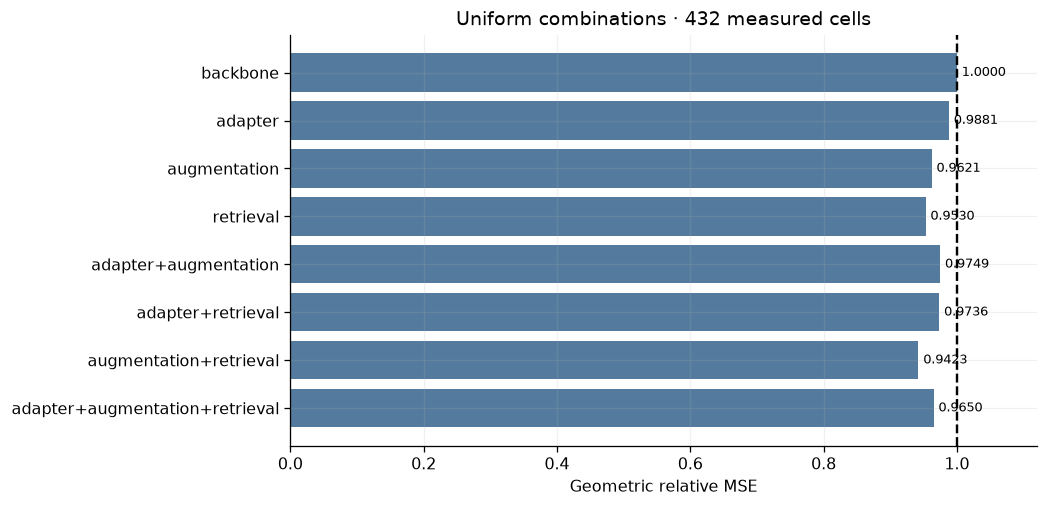

,method,relative_mse,relative_mae,wins,cells
0,uniform_demo,0.95304,0.98912,339,432
1,risk_retrieval,0.94693,0.98681,345,432
2,validation_best_retrieval,0.98043,0.99984,156,432


In [2]:
main = load_snapshot('main')
families = main[main.method.str.startswith('families/') | (main.method=='backbone')]
family_table = summarize(families)
display(family_table)
fig, ax = plt.subplots(figsize=(9, 4.3), layout='constrained')
bars = ax.barh(family_table.method.str.replace('families/', '', regex=False), family_table.relative_mse, color='#547b9e')
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8); ax.invert_yaxis()
ax.axvline(1, color='black', ls='--'); ax.set_xlim(0, family_table.relative_mse.max()*1.12)
ax.set(xlabel='Geometric relative MSE', title='Uniform combinations · 432 measured cells')
plt.show()
display(summarize(load_snapshot('retrieval')))


Retrieval-demo uses ten independently aligned one-demo forecasts plus identity. A top-10
retrieval list does not imply concatenating ten demonstrations. Uniform/risk/validation-best
aggregation is measured explicitly; the code does not assume retrieval must improve a frozen backbone.

## Adapter samples: five to forty
Bolt-S, Bolt-B and TimesFM × ETTh1, ETTm1 and Appliances × eight N values;
H=96, seed=0. Each N refits the Adapter and Risk regressor. All-view candidates number
`1+3*(N-1)`; N is the size of each delta grid, not the total pool size.


,num_samples,method,relative_mse,relative_mae,wins,cells
0,10,risk_all,0.99093,1.00608,7,9
6,15,risk_all,0.99015,1.00572,7,9
12,20,risk_all,0.99051,1.00562,7,9
18,25,risk_all,0.98881,1.00455,7,9
24,30,risk_all,0.98896,1.00426,7,9
30,35,risk_all,0.98992,1.00543,7,9
36,40,risk_all,0.99066,1.00548,7,9
42,5,risk_all,0.99018,1.00700,7,9


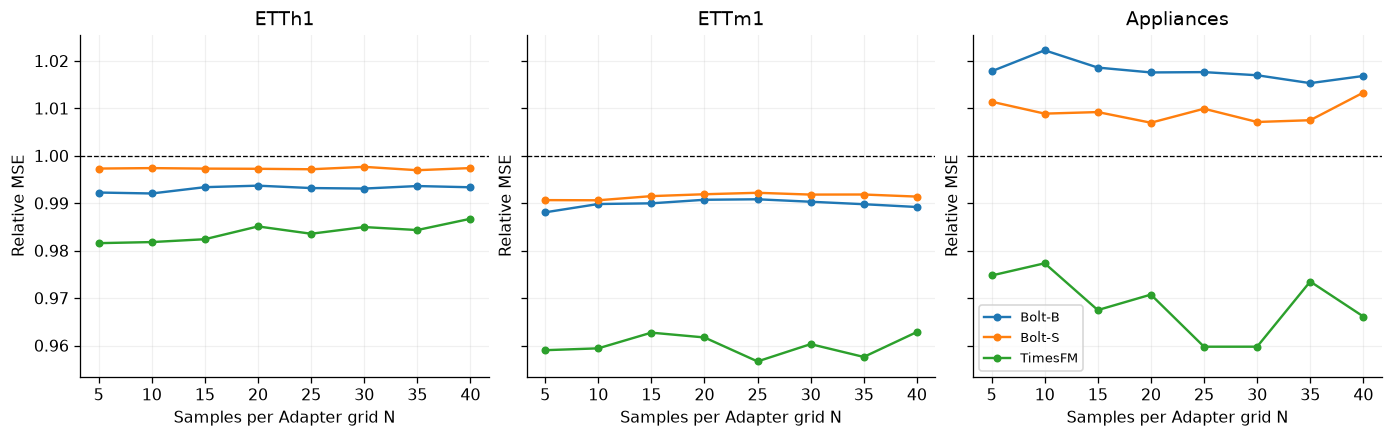

Monotonically nonincreasing Risk curves: 0/9


In [3]:
sweep = load_snapshot('adapters')
assert len(sweep) == 72*6
sweep_table = summarize(sweep, ['num_samples','method'])
display(sweep_table[sweep_table.method=='risk_all'])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout='constrained', sharey=True)
for ax, dataset in zip(axes, ['ETTh1','ETTm1','Appliances']):
    for model, group in sweep[(sweep.dataset==dataset) & (sweep.method=='risk_all')].groupby('model'):
        curve = group.sort_values('num_samples')
        ax.plot(curve.num_samples, curve.relative_mse, 'o-', label=MODEL_LABELS[model], ms=4)
    ax.axhline(1, color='black', ls='--', lw=.8)
    ax.set(title=dataset, xlabel='Samples per Adapter grid N', ylabel='Relative MSE')
    ax.set_xticks([5,10,15,20,25,30,35,40])
axes[-1].legend(fontsize=8); plt.show()
curves = sweep[sweep.method=='risk_all'].sort_values('num_samples').groupby(['model','dataset'])
monotone = sum(np.all(np.diff(group.relative_mse)<=1e-10) for _, group in curves)
print(f'Monotonically nonincreasing Risk curves: {monotone}/{len(curves)}')


More samples do not guarantee lower test MSE. The shared residual creates correlated
candidates; refitting adds optimization variability; a learned selector can overfit. The
paper's compute-benefit analysis states conditions and separates population optima from
finite-sample fitted performance. This one-seed sweep is a sensitivity study, not a scaling law.
